# 10 — Data drift monitoring

**Question:** the categorizer learned from one period of spending. How do I notice when new data stops looking like that?

Three checks, each comparing a **reference** window (year 1, what a model would be trained on) to each later **month**:
1. **Category mix** — PSI (Population Stability Index)
2. **Amounts** — KS test (Kolmogorov–Smirnov)
3. **Model confidence** — share of descriptions the model is unsure about (below the app's `THRESHOLD = 0.5`)

In [1]:
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

sys.path.insert(0, '../service')
from clean import clean_description

df = pd.read_csv('../data/fake_transactions_3y.csv', parse_dates=['Date'])
df['Description'] = df['Description'].fillna('').str.strip()
exp = df[df['Type'] == 'expense'].copy()
exp['Month'] = exp['Date'].dt.tz_localize(None).dt.to_period('M')

start = exp['Date'].min()
ref = exp[exp['Date'] < start + pd.DateOffset(years=1)]
later = exp[exp['Date'] >= start + pd.DateOffset(years=1)]
months = sorted(later['Month'].unique())[1:-1]  # drop partial months at both ends (tiny samples make PSI jump)
print(f'Reference: {len(ref)} expenses, {ref.Month.min()} to {ref.Month.max()}')
print(f'Monitoring {len(months)} months: {months[0]} to {months[-1]}')

Reference: 1435 expenses, 2023-10 to 2024-10
Monitoring 23 months: 2024-11 to 2026-09


## 1. Category mix — PSI

PSI = Σ (actual% − expected%) × ln(actual% / expected%), over categories.

Rule of thumb: **< 0.1 stable**, **0.1–0.25 watch**, **> 0.25 drift**. Months are small (~120 expenses), so some noise is expected.

In [2]:
def psi(expected, actual, eps=1e-4):
    """PSI between two category->share Series. eps avoids log(0) for a category missing on one side."""
    cats = expected.index.union(actual.index)
    e = expected.reindex(cats, fill_value=0).clip(lower=eps)
    a = actual.reindex(cats, fill_value=0).clip(lower=eps)
    return float(((a - e) * np.log(a / e)).sum())

# self-check: identical = 0, big shift > 0.25
s = pd.Series({'A': 0.5, 'B': 0.5})
assert psi(s, s) == 0
assert psi(s, pd.Series({'A': 0.9, 'B': 0.1})) > 0.25

ref_mix = ref['Category'].value_counts(normalize=True)
psi_by_month = pd.Series({
    m: psi(ref_mix, later.loc[later.Month == m, 'Category'].value_counts(normalize=True))
    for m in months
})
psi_by_month.round(3).to_frame('PSI').T

,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,...,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
PSI,0.097,0.014,0.018,0.003,0.011,0.021,0.05,0.037,0.022,0.196,...,0.183,0.016,0.056,0.079,0.045,0.064,0.014,0.02,0.078,0.061


## 2. Amounts — KS test

KS compares two whole distributions. Small p-value (< 0.01 here, since I test many months) = this month's amounts look different from the reference. The KS **statistic** (0–1) says *how* different.

In [3]:
rows = []
for m in months:
    amounts = later.loc[later.Month == m, 'Amount']
    result = ks_2samp(ref['Amount'], amounts)
    rows.append({'Month': m, 'KS stat': result.statistic, 'p-value': result.pvalue, 'median': amounts.median()})
ks = pd.DataFrame(rows).set_index('Month')

print(f'Reference median amount: {ref.Amount.median():.0f}')
print(f'Months flagged (p < 0.01): {(ks["p-value"] < 0.01).sum()} of {len(ks)}')
ks.round(3).T

Reference median amount: 400
Months flagged (p < 0.01): 1 of 23


Month,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,...,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
KS stat,0.078,0.174,0.077,0.059,0.044,0.067,0.111,0.088,0.082,0.047,...,0.148,0.085,0.084,0.086,0.126,0.058,0.077,0.108,0.062,0.121
p-value,0.493,0.002,0.500,0.852,0.972,0.695,0.126,0.339,0.432,0.946,...,0.014,0.440,0.453,0.339,0.057,0.814,0.547,0.143,0.745,0.074
median,463.905,564.075,466.290,401.690,386.065,419.840,448.400,442.090,403.405,371.255,...,541.910,422.615,361.560,476.880,512.560,411.250,379.265,435.470,375.720,507.840


## 3. Model confidence

The deployed model (`service/model/categorizer.joblib`) on each month's descriptions. If the share of **unsure** predictions (top probability < 0.5, same threshold as the app) rises, the model is meeting text it doesn't know.

Then the stress test: `datasets/new_merchants.csv` — merchants the model never saw.

In [4]:
model = joblib.load('../service/model/categorizer.joblib')
THRESHOLD = 0.5

def unsure_share(descriptions):
    cleaned = [c for c in map(clean_description, descriptions) if c]
    return float((model.predict_proba(cleaned).max(axis=1) < THRESHOLD).mean())

ref_unsure = unsure_share(ref['Description'])
unsure_by_month = pd.Series({m: unsure_share(later.loc[later.Month == m, 'Description']) for m in months})

new = pd.read_csv('../datasets/new_merchants.csv')
new_unsure = unsure_share(new['description'])
new_acc = (model.predict(new['description'].map(clean_description)) == new['category']).mean()

print(f'Unsure share, reference: {ref_unsure:.1%}; later months: {unsure_by_month.min():.1%} to {unsure_by_month.max():.1%}')
print(f'Unsure share, new merchants: {new_unsure:.1%} (accuracy {new_acc:.1%})')

Unsure share, reference: 4.9%; later months: 1.9% to 8.3%
Unsure share, new merchants: 86.4% (accuracy 22.7%)


## 4. Does the alarm actually fire?

The fake data may be too stable to cross 0.25 on its own. So I build a **drifted month** on purpose from the last real month: Food halves and Shopping grows by the same amount (e.g. a switch to online shopping). A working monitor must flag it.

In [5]:
base = later[later.Month == months[-1]]
food = base[base.Category == 'Food & Drinks']
shop = base[base.Category == 'Shopping']
drifted = pd.concat([
    base[base.Category != 'Food & Drinks'],
    food.sample(frac=0.5, random_state=42),                       # half the food
    shop.sample(n=len(food) // 2, replace=True, random_state=42),  # that much more shopping
])
drifted_psi = psi(ref_mix, drifted['Category'].value_counts(normalize=True))
print(f'Real last month PSI: {psi_by_month.iloc[-1]:.3f}   Drifted month PSI: {drifted_psi:.3f}')
assert drifted_psi > 0.25, 'monitor failed to flag an obvious shift'

Real last month PSI: 0.061   Drifted month PSI: 0.440


## 5. Dashboard

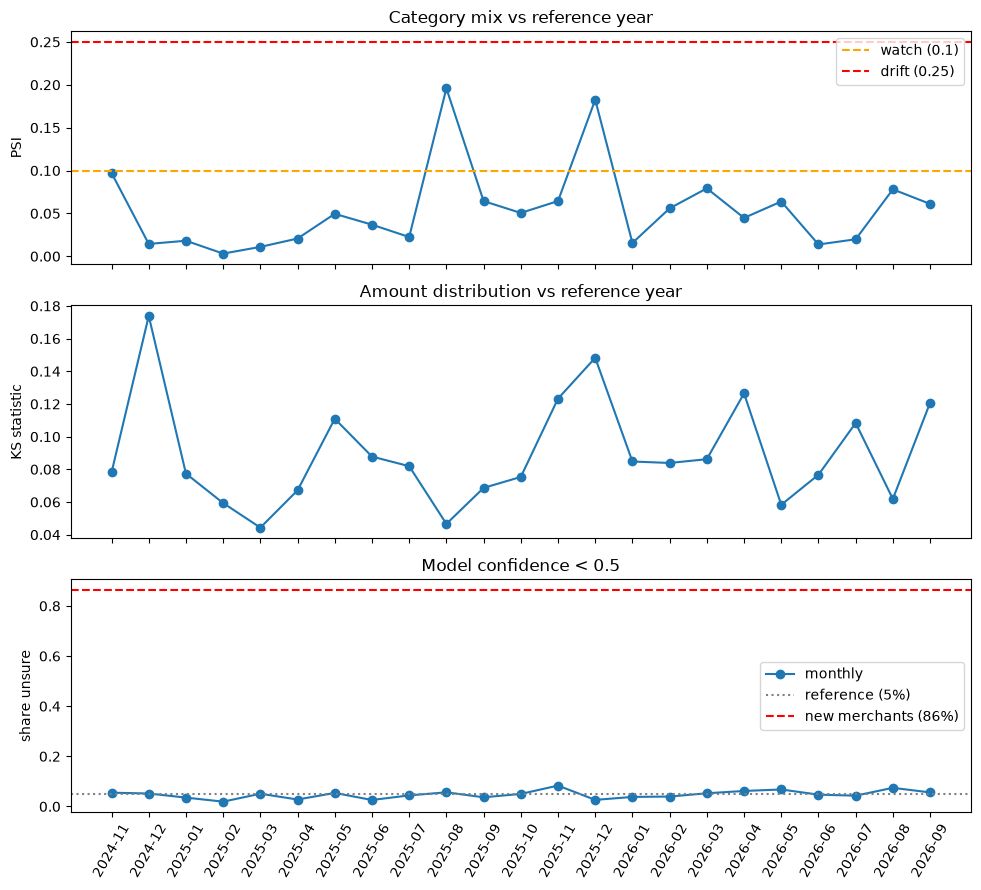

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
x = [str(m) for m in months]

axes[0].plot(x, psi_by_month.values, marker='o')
axes[0].axhline(0.1, color='orange', ls='--', label='watch (0.1)')
axes[0].axhline(0.25, color='red', ls='--', label='drift (0.25)')
axes[0].set_ylabel('PSI'); axes[0].set_title('Category mix vs reference year'); axes[0].legend()

axes[1].plot(x, ks['KS stat'].values, marker='o')
axes[1].set_ylabel('KS statistic'); axes[1].set_title('Amount distribution vs reference year')

axes[2].plot(x, unsure_by_month.values, marker='o', label='monthly')
axes[2].axhline(ref_unsure, color='gray', ls=':', label=f'reference ({ref_unsure:.0%})')
axes[2].axhline(new_unsure, color='red', ls='--', label=f'new merchants ({new_unsure:.0%})')
axes[2].set_ylabel('share unsure'); axes[2].set_title('Model confidence < 0.5'); axes[2].legend()

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [7]:
summary = pd.DataFrame({
    'PSI': psi_by_month.round(3),
    'PSI flag': pd.cut(psi_by_month, [-1, 0.1, 0.25, 99], labels=['ok', 'watch', 'DRIFT']),
    'KS p<0.01': ks['p-value'] < 0.01,
    'unsure %': (unsure_by_month * 100).round(1),
})
print(summary['PSI flag'].value_counts().to_dict())
summary

{'ok': 21, 'watch': 2, 'DRIFT': 0}


,PSI,PSI flag,KS p<0.01,unsure %
2024-11,0.097,ok,False,5.5
2024-12,0.014,ok,True,5.2
2025-01,0.018,ok,False,3.5
2025-02,0.003,ok,False,1.9
2025-03,0.011,ok,False,5.1
2025-04,0.021,ok,False,2.8
2025-05,0.050,ok,False,5.4
2025-06,0.037,ok,False,2.6
2025-07,0.022,ok,False,4.4
2025-08,0.196,watch,False,5.6


## What I learned

- **My spending barely drifts.** Over 23 months, PSI never crossed 0.25; only two months reached "watch" (Aug and Dec 2025), and Decembers also show up in the KS test as bigger amounts. Seasonal, not a broken model.
- **The model's real risk is new merchants, not changing habits.** Monthly unsure rates stayed at 2–8% (5% in the reference year), but on merchants it never saw, 86% of predictions were unsure and only 23% correct. TF-IDF knows letter patterns of names it was trained on, nothing about what a shop sells.
- **So confidence is the alarm to watch for this app.** PSI and KS describe the data; the unsure share tells me directly when the model is struggling.
- **Test the alarm, not just the data.** The real data never triggered it, so I planted a shift (Food halved, Shopping up) and PSI jumped to 0.44. Without that I couldn't tell "no drift" from "monitor doesn't work".
- **Small samples lie.** A 9-day partial month gave PSI 0.36, a fake drift. Monitoring windows need enough rows.
- **When it fires:** label the new merchants, add them to training, retrain with the CI workflow, and check accuracy on a held-out set of unseen merchants, not just a random split.